In [1]:
"""
================================================================================
Tesla Stock DIRECTION Classification Pipeline (binary: up vs down)
================================================================================
Task: predict sign(price_{t+1} - price_t)  ->  1 if up, 0 if down
Dataset size: ~1037 points (SMALL - design choices reflect this)

Models:
  1. Naive baselines (always-up, persistence, majority class)
  2. Logistic Regression on engineered features (sanity check)
  3. Improved LSTM classifier with hyperparameter tuning
  4. Temporal Fusion Transformer (simplified) classifier
  5. N-BEATS classifier (logits head)

Best practices for small data + classification:
  - Split BEFORE normalize
  - TimeSeriesSplit for walk-forward CV
  - SMALL models (1037 points cannot support large LSTMs)
  - Class weights for imbalance
  - Threshold tuning on validation set (don't blindly use 0.5)
  - Metrics: Accuracy, Balanced Accuracy, F1, MCC, ROC-AUC, Brier score
  - EarlyStopping + ReduceLROnPlateau
  - BayesianOptimization (fewer trials given small data)
  - Mean +/- std across folds, compared against naive baselines
================================================================================
"""

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Input, Dense, LSTM, Dropout, Layer, BatchNormalization,
    LayerNormalization, MultiHeadAttention, GlobalAveragePooling1D,
    Add, Subtract
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, matthews_corrcoef,
    roc_auc_score, brier_score_loss, confusion_matrix, classification_report
)
import keras_tuner as kt

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

2026-05-04 00:59:20.639668: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-04 00:59:20.650750: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-05-04 00:59:20.690241: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-05-04 00:59:20.690270: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-05-04 00:59:20.690300: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

In [2]:


# ============================================================================
# 1. CONFIG  (tuned for small data)
# ============================================================================
CSV_PATH    = "brian_news_stocks_tesla_2023_processses_with_agg.csv"
TARGET_COL  = "close"
TIME_COL    = "timestamp"
LOOKBACK    = 20         # smaller than 30 -> more training samples for tiny dataset
N_SPLITS    = 5
MAX_TRIALS  = 10         # tuner trials - keep low for small data
TUNE_EPOCHS = 25
FIT_EPOCHS  = 100
BATCH_SIZE  = 32         # smaller batch helps with limited data

# ============================================================================
# 2. UTILITIES
# ============================================================================
def create_classification_windows(prices, look_back=LOOKBACK):
    """
    X: rolling windows of returns (stationary input).
    y: 1 if next price > current price, else 0.
    """
    returns = np.diff(prices, prepend=prices[0])  # daily returns
    X, y = [], []
    for i in range(len(returns) - look_back - 1):
        # Input: window of past returns ending at time t
        window = returns[i + 1 : i + 1 + look_back]   # length look_back
        # Label: did price go UP from t to t+1?
        future_return = prices[i + 1 + look_back] - prices[i + look_back]
        X.append(window)
        y.append(1 if future_return > 0 else 0)
    return np.array(X, dtype="float32"), np.array(y, dtype="int32")


def classification_metrics(y_true, y_pred_proba, threshold=0.5):
    """Comprehensive classification metrics for binary direction prediction."""
    y_true = np.asarray(y_true).flatten()
    y_proba = np.asarray(y_pred_proba).flatten()
    y_pred = (y_proba >= threshold).astype(int)

    metrics = {
        "Accuracy":     accuracy_score(y_true, y_pred),
        "BalancedAcc":  balanced_accuracy_score(y_true, y_pred),
        "F1":           f1_score(y_true, y_pred, zero_division=0),
        "MCC":          matthews_corrcoef(y_true, y_pred),
        "Brier":        brier_score_loss(y_true, y_proba),
    }
    # ROC-AUC needs both classes present
    if len(np.unique(y_true)) > 1:
        metrics["ROC-AUC"] = roc_auc_score(y_true, y_proba)
    else:
        metrics["ROC-AUC"] = np.nan
    return metrics


def find_best_threshold(y_true, y_proba):
    """Pick threshold that maximizes balanced accuracy on validation."""
    best_t, best_score = 0.5, -1
    for t in np.linspace(0.3, 0.7, 41):
        y_pred = (y_proba >= t).astype(int)
        score = balanced_accuracy_score(y_true, y_pred)
        if score > best_score:
            best_score, best_t = score, t
    return best_t


def summarize(metrics_list, name=""):
    keys = metrics_list[0].keys()
    print(f"\n=== {name} (mean +/- std across {len(metrics_list)} folds) ===")
    for k in keys:
        vals = [m[k] for m in metrics_list if not np.isnan(m[k])]
        if vals:
            print(f"  {k:13s}: {np.mean(vals):7.4f} +/- {np.std(vals):.4f}")

In [3]:


# ============================================================================
# 3. LOAD DATA
# ============================================================================
df = pd.read_csv(CSV_PATH).sort_values(by=TIME_COL).reset_index(drop=True)
prices = df[TARGET_COL].values.astype("float32")
print(f"Data: {len(prices)} rows")

X_all, y_all = create_classification_windows(prices, LOOKBACK)
print(f"Windows: {len(X_all)} | up days: {y_all.sum()} ({y_all.mean()*100:.1f}%) "
      f"| down days: {(1-y_all).sum()} ({(1-y_all.mean())*100:.1f}%)")


Data: 1037 rows
Windows: 1016 | up days: 516 (50.8%) | down days: 500 (49.2%)


In [5]:

# ============================================================================
# 4. NAIVE BASELINES
# ============================================================================
def evaluate_naive_baselines(X, y, n_splits=N_SPLITS):
    """Three baselines every model must beat."""
    tscv = TimeSeriesSplit(n_splits=n_splits)
    results = {"Always-Up": [], "Always-Down": [], "Majority-Class": [],
               "Persistence": []}
    for fold, (tr_idx, te_idx) in enumerate(tscv.split(X), 1):
        y_tr, y_te = y[tr_idx], y[te_idx]
        X_te = X[te_idx]

        # 1) Always predict up
        results["Always-Up"].append(
            classification_metrics(y_te, np.ones(len(y_te))))
        # 2) Always predict down
        results["Always-Down"].append(
            classification_metrics(y_te, np.zeros(len(y_te))))
        # 3) Majority class on training set
        maj = int(y_tr.mean() >= 0.5)
        results["Majority-Class"].append(
            classification_metrics(y_te, np.full(len(y_te), maj)))
        # 4) Persistence: predict same direction as last observed return
        last_returns = X_te[:, -1]   # last value in window = last return
        pred = (last_returns > 0).astype(int)
        results["Persistence"].append(classification_metrics(y_te, pred))
    return results

In [6]:




# ============================================================================
# 5. LOGISTIC REGRESSION (sanity check on engineered features)
# ============================================================================
def engineered_features(X):
    """Hand-crafted features from the return window."""
    return np.column_stack([
        X.mean(axis=1),
        X.std(axis=1),
        X[:, -1],                           # last return
        X[:, -3:].mean(axis=1),             # last 3-day avg
        (X > 0).mean(axis=1),               # up-day fraction in window
        X.max(axis=1),
        X.min(axis=1),
    ])


def run_logreg(X, y):
    print("\n>>> Logistic Regression on engineered features")
    tscv = TimeSeriesSplit(n_splits=N_SPLITS)
    fold_metrics = []
    for fold, (tr_idx, te_idx) in enumerate(tscv.split(X), 1):
        X_tr, X_te = engineered_features(X[tr_idx]), engineered_features(X[te_idx])
        y_tr, y_te = y[tr_idx], y[te_idx]
        sc = StandardScaler().fit(X_tr)
        X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)

        clf = LogisticRegression(class_weight="balanced", max_iter=1000)
        clf.fit(X_tr, y_tr)
        proba = clf.predict_proba(X_te)[:, 1]
        m = classification_metrics(y_te, proba)
        fold_metrics.append(m)
        print(f"  LogReg fold {fold}: BalAcc={m['BalancedAcc']:.4f} "
              f"F1={m['F1']:.4f} MCC={m['MCC']:.4f}")
    return fold_metrics



NAIVE BASELINES

=== Always-Up (mean +/- std across 5 folds) ===
  Accuracy     :  0.5041 +/- 0.0342
  BalancedAcc  :  0.5000 +/- 0.0000
  F1           :  0.6697 +/- 0.0301
  MCC          :  0.0000 +/- 0.0000
  Brier        :  0.4959 +/- 0.0342
  ROC-AUC      :  0.5000 +/- 0.0000

=== Always-Down (mean +/- std across 5 folds) ===
  Accuracy     :  0.4959 +/- 0.0342
  BalancedAcc  :  0.5000 +/- 0.0000
  F1           :  0.0000 +/- 0.0000
  MCC          :  0.0000 +/- 0.0000
  Brier        :  0.5041 +/- 0.0342
  ROC-AUC      :  0.5000 +/- 0.0000

=== Majority-Class (mean +/- std across 5 folds) ===
  Accuracy     :  0.4864 +/- 0.0316
  BalancedAcc  :  0.5000 +/- 0.0000
  F1           :  0.5287 +/- 0.2655
  MCC          :  0.0000 +/- 0.0000
  Brier        :  0.5136 +/- 0.0316
  ROC-AUC      :  0.5000 +/- 0.0000

=== Persistence (mean +/- std across 5 folds) ===
  Accuracy     :  0.4994 +/- 0.0271
  BalancedAcc  :  0.4972 +/- 0.0263
  F1           :  0.5005 +/- 0.0562
  MCC          : -0.00

2026-05-04 01:00:18.989348: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


  Best HPs: {'num_layers': 1, 'units_0': 64, 'dropout_0': 0.5, 'lr': 0.01, 'units_1': 32, 'dropout_1': 0.30000000000000004}
  LSTM fold 1: BalAcc=0.4872 F1=0.6034 MCC=-0.0449 thr=0.42
  LSTM fold 2: BalAcc=0.5246 F1=0.4354 MCC=0.0522 thr=0.52
  LSTM fold 3: BalAcc=0.5110 F1=0.6557 MCC=0.0518 thr=0.41
  LSTM fold 4: BalAcc=0.5056 F1=0.3594 MCC=0.0125 thr=0.55
  LSTM fold 5: BalAcc=0.5224 F1=0.4503 MCC=0.0469 thr=0.57

=== LSTM (mean +/- std across 5 folds) ===
  Accuracy     :  0.4982 +/- 0.0216
  BalancedAcc  :  0.5102 +/- 0.0135
  F1           :  0.5009 +/- 0.1108
  MCC          :  0.0237 +/- 0.0374
  Brier        :  0.2534 +/- 0.0046
  ROC-AUC      :  0.5408 +/- 0.0151
  Threshold    :  0.4940 +/- 0.0665

TFT CLASSIFIER

>>> TFT Classifier
  Best HPs: {'units': 64, 'n_heads': 2, 'dropout': 0.2, 'lr': 0.0001}
  TFT fold 1: BalAcc=0.5137 F1=0.4030 MCC=0.0291 thr=0.54
  TFT fold 2: BalAcc=0.5077 F1=0.1000 MCC=0.0361 thr=0.55
  TFT fold 3: BalAcc=0.4817 F1=0.6397 MCC=-0.1079 thr=0.45
  T

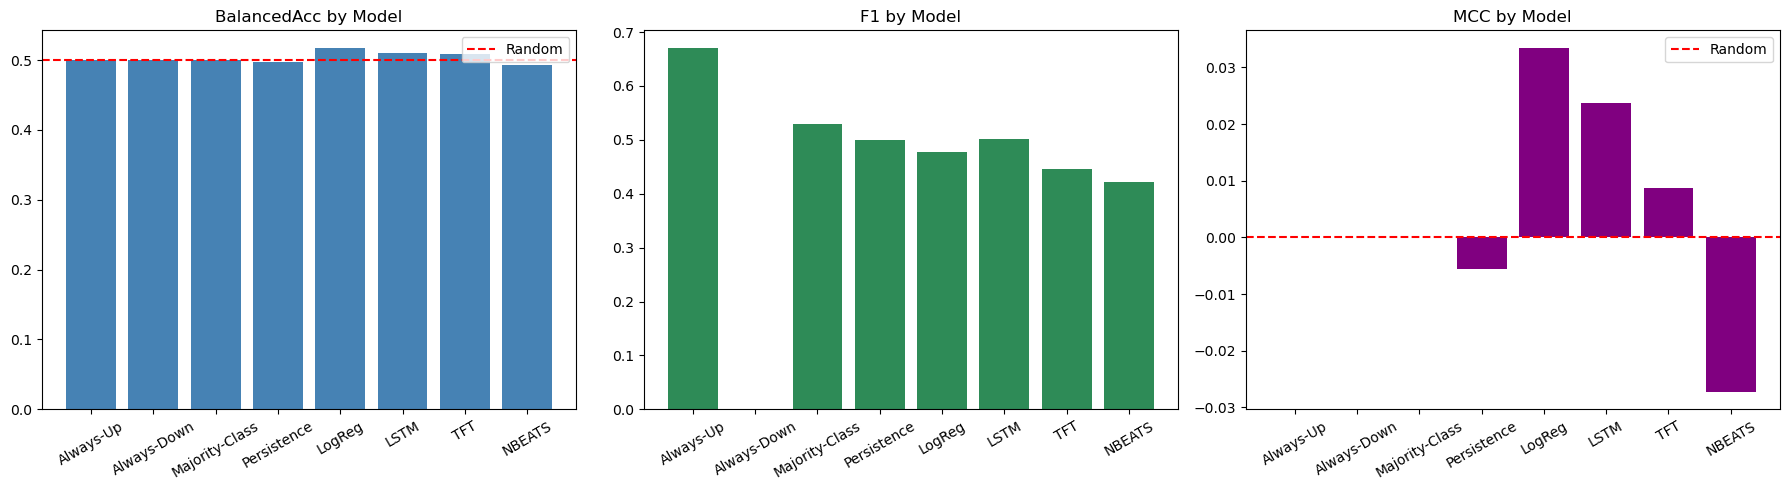

Saved -> classification_comparison.png


In [7]:



# ============================================================================
# 6. LSTM CLASSIFIER
# ============================================================================
def build_lstm_classifier(hp, look_back=LOOKBACK, n_features=1):
    """SMALL LSTM - 1037 datapoints cannot support a deep model."""
    model = Sequential()
    n_layers = hp.Int("num_layers", 1, 2)
    for i in range(n_layers):
        units = hp.Int(f"units_{i}", 16, 64, step=16)        # small!
        dropout = hp.Float(f"dropout_{i}", 0.1, 0.5, step=0.1)
        return_sequences = (i < n_layers - 1)
        if i == 0:
            model.add(LSTM(units, return_sequences=return_sequences,
                           input_shape=(look_back, n_features)))
        else:
            model.add(LSTM(units, return_sequences=return_sequences))
        model.add(Dropout(dropout))
    model.add(Dense(1, activation="sigmoid"))     # binary output
    lr = hp.Choice("lr", [1e-2, 1e-3, 1e-4])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
    )
    return model


def tune_classifier(builder, X_train, y_train, project_name, class_weight=None):
    """Bayesian search on a single train/val slice."""
    val_split = int(len(X_train) * 0.8)
    X_tr, X_va = X_train[:val_split], X_train[val_split:]
    y_tr, y_va = y_train[:val_split], y_train[val_split:]

    tuner = kt.BayesianOptimization(
        builder,
        objective=kt.Objective("val_auc", direction="max"),
        max_trials=MAX_TRIALS,
        directory="kt_dir_cls",
        project_name=project_name,
        overwrite=True,
        seed=SEED,
    )
    es = EarlyStopping(monitor="val_auc", mode="max", patience=8,
                       min_delta=1e-4, restore_best_weights=True)
    tuner.search(X_tr, y_tr, epochs=TUNE_EPOCHS,
                 validation_data=(X_va, y_va),
                 class_weight=class_weight,
                 callbacks=[es], verbose=0)
    return tuner.get_best_hyperparameters(1)[0]


def run_lstm_classifier(X_all, y_all):
    print("\n>>> LSTM Classifier")
    X_seq = X_all.reshape(-1, LOOKBACK, 1)

    # Tune on first 70%
    split = int(len(X_seq) * 0.7)
    cw_arr = compute_class_weight("balanced",
                                  classes=np.unique(y_all[:split]),
                                  y=y_all[:split])
    cw = {i: w for i, w in enumerate(cw_arr)}
    best_hp = tune_classifier(build_lstm_classifier,
                              X_seq[:split], y_all[:split],
                              "lstm_cls", class_weight=cw)
    print(f"  Best HPs: {best_hp.values}")

    tscv = TimeSeriesSplit(n_splits=N_SPLITS)
    fold_metrics = []
    for fold, (tr_idx, te_idx) in enumerate(tscv.split(X_seq), 1):
        X_tr_raw, X_te_raw = X_seq[tr_idx], X_seq[te_idx]
        y_tr, y_te = y_all[tr_idx], y_all[te_idx]

        # Scale on TRAIN only
        sc = StandardScaler().fit(X_tr_raw.reshape(-1, 1))
        X_tr = sc.transform(X_tr_raw.reshape(-1, 1)).reshape(X_tr_raw.shape)
        X_te = sc.transform(X_te_raw.reshape(-1, 1)).reshape(X_te_raw.shape)

        # Carve a small validation slice for threshold tuning + early stopping
        val_split = int(len(X_tr) * 0.85)
        X_t, X_v = X_tr[:val_split], X_tr[val_split:]
        y_t, y_v = y_tr[:val_split], y_tr[val_split:]

        # Class weights from this fold's training data
        cw_arr = compute_class_weight("balanced",
                                      classes=np.unique(y_t), y=y_t)
        cw = {i: w for i, w in enumerate(cw_arr)}

        model = build_lstm_classifier(best_hp)
        callbacks = [
            EarlyStopping(monitor="val_auc", mode="max", patience=15,
                          min_delta=1e-4, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", patience=6, factor=0.5),
        ]
        model.fit(X_t, y_t, epochs=FIT_EPOCHS, batch_size=BATCH_SIZE,
                  validation_data=(X_v, y_v),
                  class_weight=cw, callbacks=callbacks, verbose=0)

        # Threshold tuning on validation
        val_proba = model.predict(X_v, verbose=0).flatten()
        best_t = find_best_threshold(y_v, val_proba)

        # Test predictions
        test_proba = model.predict(X_te, verbose=0).flatten()
        m = classification_metrics(y_te, test_proba, threshold=best_t)
        m["Threshold"] = best_t
        fold_metrics.append(m)
        print(f"  LSTM fold {fold}: BalAcc={m['BalancedAcc']:.4f} "
              f"F1={m['F1']:.4f} MCC={m['MCC']:.4f} thr={best_t:.2f}")
    return fold_metrics


# ============================================================================
# 7. TFT CLASSIFIER  (simplified)
# ============================================================================
def gated_residual_network(x, units, dropout=0.1):
    h = Dense(units, activation="elu")(x)
    h = Dense(units)(h)
    h = Dropout(dropout)(h)
    gate = Dense(units, activation="sigmoid")(x)
    if x.shape[-1] != units:
        x = Dense(units)(x)
    return LayerNormalization()(Add()([x, h * gate]))


def build_tft_classifier(hp, look_back=LOOKBACK, n_features=1):
    units    = hp.Int("units", 16, 64, step=16)            # small for 1037 pts
    n_heads  = hp.Choice("n_heads", [2, 4])
    dropout  = hp.Float("dropout", 0.1, 0.4, step=0.1)
    lr       = hp.Choice("lr", [1e-3, 5e-4, 1e-4])

    inp = Input(shape=(look_back, n_features))
    enc = LSTM(units, return_sequences=True)(inp)
    enc = gated_residual_network(enc, units, dropout)
    attn = MultiHeadAttention(num_heads=n_heads, key_dim=units)(enc, enc)
    attn = Dropout(dropout)(attn)
    x = LayerNormalization()(Add()([enc, attn]))
    x = gated_residual_network(x, units, dropout)
    x = GlobalAveragePooling1D()(x)
    out = Dense(1, activation="sigmoid")(x)
    model = Model(inp, out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
    )
    return model


def run_tft_classifier(X_all, y_all):
    print("\n>>> TFT Classifier")
    X_seq = X_all.reshape(-1, LOOKBACK, 1)

    split = int(len(X_seq) * 0.7)
    cw_arr = compute_class_weight("balanced",
                                  classes=np.unique(y_all[:split]),
                                  y=y_all[:split])
    cw = {i: w for i, w in enumerate(cw_arr)}
    best_hp = tune_classifier(build_tft_classifier,
                              X_seq[:split], y_all[:split],
                              "tft_cls", class_weight=cw)
    print(f"  Best HPs: {best_hp.values}")

    tscv = TimeSeriesSplit(n_splits=N_SPLITS)
    fold_metrics = []
    for fold, (tr_idx, te_idx) in enumerate(tscv.split(X_seq), 1):
        X_tr_raw, X_te_raw = X_seq[tr_idx], X_seq[te_idx]
        y_tr, y_te = y_all[tr_idx], y_all[te_idx]

        sc = StandardScaler().fit(X_tr_raw.reshape(-1, 1))
        X_tr = sc.transform(X_tr_raw.reshape(-1, 1)).reshape(X_tr_raw.shape)
        X_te = sc.transform(X_te_raw.reshape(-1, 1)).reshape(X_te_raw.shape)

        val_split = int(len(X_tr) * 0.85)
        X_t, X_v = X_tr[:val_split], X_tr[val_split:]
        y_t, y_v = y_tr[:val_split], y_tr[val_split:]
        cw_arr = compute_class_weight("balanced",
                                      classes=np.unique(y_t), y=y_t)
        cw = {i: w for i, w in enumerate(cw_arr)}

        model = build_tft_classifier(best_hp)
        callbacks = [
            EarlyStopping(monitor="val_auc", mode="max", patience=15,
                          min_delta=1e-4, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", patience=6, factor=0.5),
        ]
        model.fit(X_t, y_t, epochs=FIT_EPOCHS, batch_size=BATCH_SIZE,
                  validation_data=(X_v, y_v),
                  class_weight=cw, callbacks=callbacks, verbose=0)

        val_proba = model.predict(X_v, verbose=0).flatten()
        best_t = find_best_threshold(y_v, val_proba)
        test_proba = model.predict(X_te, verbose=0).flatten()
        m = classification_metrics(y_te, test_proba, threshold=best_t)
        m["Threshold"] = best_t
        fold_metrics.append(m)
        print(f"  TFT fold {fold}: BalAcc={m['BalancedAcc']:.4f} "
              f"F1={m['F1']:.4f} MCC={m['MCC']:.4f} thr={best_t:.2f}")
    return fold_metrics


# ============================================================================
# 8. N-BEATS CLASSIFIER
# ============================================================================
def nbeats_block(x, units, look_back):
    h = x
    for _ in range(4):
        h = Dense(units, activation="relu")(h)
    backcast = Dense(look_back, activation="linear")(h)
    forecast = Dense(units, activation="linear")(h)   # block-level "forecast feature"
    return backcast, forecast


def build_nbeats_classifier(hp, look_back=LOOKBACK):
    units      = hp.Int("units", 32, 128, step=32)
    n_blocks   = hp.Int("n_blocks", 2, 4)
    dropout    = hp.Float("dropout", 0.1, 0.4, step=0.1)
    lr         = hp.Choice("lr", [1e-3, 5e-4, 1e-4])

    inp = Input(shape=(look_back,))
    residual = inp
    forecast_sum = None
    for _ in range(n_blocks):
        backcast, fc = nbeats_block(residual, units, look_back)
        residual = Subtract()([residual, backcast])
        forecast_sum = fc if forecast_sum is None else Add()([forecast_sum, fc])

    x = Dropout(dropout)(forecast_sum)
    out = Dense(1, activation="sigmoid")(x)
    model = Model(inp, out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
    )
    return model


def run_nbeats_classifier(X_all, y_all):
    print("\n>>> N-BEATS Classifier")
    # N-BEATS uses flat 1D windows, no need to reshape

    split = int(len(X_all) * 0.7)
    cw_arr = compute_class_weight("balanced",
                                  classes=np.unique(y_all[:split]),
                                  y=y_all[:split])
    cw = {i: w for i, w in enumerate(cw_arr)}
    best_hp = tune_classifier(build_nbeats_classifier,
                              X_all[:split], y_all[:split],
                              "nbeats_cls", class_weight=cw)
    print(f"  Best HPs: {best_hp.values}")

    tscv = TimeSeriesSplit(n_splits=N_SPLITS)
    fold_metrics = []
    for fold, (tr_idx, te_idx) in enumerate(tscv.split(X_all), 1):
        X_tr_raw, X_te_raw = X_all[tr_idx], X_all[te_idx]
        y_tr, y_te = y_all[tr_idx], y_all[te_idx]

        sc = StandardScaler().fit(X_tr_raw.reshape(-1, 1))
        X_tr = sc.transform(X_tr_raw.reshape(-1, 1)).reshape(X_tr_raw.shape)
        X_te = sc.transform(X_te_raw.reshape(-1, 1)).reshape(X_te_raw.shape)

        val_split = int(len(X_tr) * 0.85)
        X_t, X_v = X_tr[:val_split], X_tr[val_split:]
        y_t, y_v = y_tr[:val_split], y_tr[val_split:]
        cw_arr = compute_class_weight("balanced",
                                      classes=np.unique(y_t), y=y_t)
        cw = {i: w for i, w in enumerate(cw_arr)}

        model = build_nbeats_classifier(best_hp)
        callbacks = [
            EarlyStopping(monitor="val_auc", mode="max", patience=15,
                          min_delta=1e-4, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", patience=6, factor=0.5),
        ]
        model.fit(X_t, y_t, epochs=FIT_EPOCHS, batch_size=BATCH_SIZE,
                  validation_data=(X_v, y_v),
                  class_weight=cw, callbacks=callbacks, verbose=0)

        val_proba = model.predict(X_v, verbose=0).flatten()
        best_t = find_best_threshold(y_v, val_proba)
        test_proba = model.predict(X_te, verbose=0).flatten()
        m = classification_metrics(y_te, test_proba, threshold=best_t)
        m["Threshold"] = best_t
        fold_metrics.append(m)
        print(f"  NBEATS fold {fold}: BalAcc={m['BalancedAcc']:.4f} "
              f"F1={m['F1']:.4f} MCC={m['MCC']:.4f} thr={best_t:.2f}")
    return fold_metrics


# ============================================================================
# 9. MAIN
# ============================================================================
if __name__ == "__main__":
    results = {}

    print("\n" + "="*70)
    print("NAIVE BASELINES")
    print("="*70)
    naive = evaluate_naive_baselines(X_all, y_all)
    for name, folds in naive.items():
        results[name] = folds
        summarize(folds, name)

    print("\n" + "="*70)
    print("LOGISTIC REGRESSION (engineered features sanity check)")
    print("="*70)
    results["LogReg"] = run_logreg(X_all, y_all)
    summarize(results["LogReg"], "LogReg")

    print("\n" + "="*70)
    print("LSTM CLASSIFIER")
    print("="*70)
    results["LSTM"] = run_lstm_classifier(X_all, y_all)
    summarize(results["LSTM"], "LSTM")

    print("\n" + "="*70)
    print("TFT CLASSIFIER")
    print("="*70)
    results["TFT"] = run_tft_classifier(X_all, y_all)
    summarize(results["TFT"], "TFT")

    print("\n" + "="*70)
    print("N-BEATS CLASSIFIER")
    print("="*70)
    results["NBEATS"] = run_nbeats_classifier(X_all, y_all)
    summarize(results["NBEATS"], "NBEATS")

    # ---------------------------------------------------------------
    # Comparison table
    # ---------------------------------------------------------------
    print("\n" + "="*70)
    print("FINAL COMPARISON (mean across folds)")
    print("="*70)
    rows = []
    metric_keys = ["Accuracy", "BalancedAcc", "F1", "MCC", "ROC-AUC", "Brier"]
    for name, folds in results.items():
        avg = {k: np.nanmean([f.get(k, np.nan) for f in folds])
               for k in metric_keys}
        rows.append({"Model": name, **avg})
    df_out = pd.DataFrame(rows).round(4)
    print(df_out.to_string(index=False))
    df_out.to_csv("classification_comparison.csv", index=False)
    print("\nSaved -> classification_comparison.csv")

    # Plot comparison
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, metric, color in zip(
        axes, ["BalancedAcc", "F1", "MCC"], ["steelblue", "seagreen", "purple"]
    ):
        ax.bar(df_out["Model"], df_out[metric], color=color)
        ax.set_title(f"{metric} by Model")
        ax.tick_params(axis="x", rotation=30)
        if metric == "BalancedAcc":
            ax.axhline(0.5, color="red", linestyle="--", label="Random")
            ax.legend()
        elif metric == "MCC":
            ax.axhline(0, color="red", linestyle="--", label="Random")
            ax.legend()
    plt.tight_layout()
    plt.savefig("classification_comparison.png", dpi=120)
    plt.show()
    print("Saved -> classification_comparison.png")